# DSA 4060XA – Week 6: Evaluating Recommender Systems
**Name:** Ilham  |  **Student ID:** [670152]

**Models compared:** Popularity Baseline, Content-Based Filtering, Item-Based Collaborative Filtering (CF)

## Step 1 – Import the Required Libraries

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 3

## Step 2 – Load and Inspect the Data

In [23]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")

display(movies.head())
display(ratings.head())

print("Users:", ratings["user_id"].nunique())
print("Movies:", ratings["movie_id"].nunique())
print("Ratings:", len(ratings))

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120


**Student Check**
1. One row in `movies` = one movie (its id, title and genres).
2. One row in `ratings` = one rating that one user gave to one movie. `timestamp` is the order in which the user rated.
3. 12 unique users, 20 unique movies, 120 ratings (every user rated 10 movies).
4. `rating` is **explicit** feedback (the user directly told us how much they liked the movie).
5. The scale is 1–5. In this data the ratings seen are 2, 3, 4 and 5 (no 1s).

## Step 3 – Inspect Rating Behaviour

rating
2    29
3    49
4    28
5    14
Name: count, dtype: int64

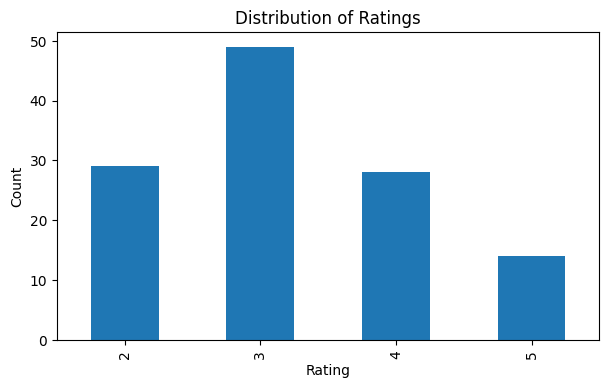

In [24]:
display(ratings["rating"].value_counts().sort_index())

plt.figure(figsize=(7,4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

**Interpretation:** Middle ratings dominate. Ratings of 2 and 3 make up 78 of 120 (65%), while 4s and 5s make up only 42 (35%) and there are no 1s. Because most ratings sit in the middle, even a simple model that guesses "about 3" will have a fairly small error, so the gap between models in MAE/RMSE will look small. It also means only a minority of held-out items will count as "relevant" (rating ≥ 4) later, so ranking metrics will be based on very few cases.

## Step 4 – Create a Train/Test Split

In [25]:
ratings = ratings.sort_values(["user_id", "timestamp"])

test = ratings.groupby("user_id").tail(1).copy()
train = ratings.drop(test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))
display(test.head())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


Each user keeps 9 ratings for training and 1 (their most recent) for testing: **108 train, 12 test**. We test on interactions the model never saw, otherwise the results would look better than they really are.

## Step 5 – Build a Popularity Baseline

In [26]:
global_mean = train["rating"].mean()

movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id")
)

display(movie_stats.sort_values(
    ["mean_rating", "rating_count"],
    ascending=[False, False]
).head(10))

movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()

baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)

,movie_id,mean_rating,rating_count,title
5,6,4.166667,6,Broken Hearts
0,1,4.000000,3,Galaxy Mission
17,18,4.000000,2,The Promise
3,4,3.800000,5,Family Weekend
9,10,3.666667,6,Hidden Truth
15,16,3.571429,7,Campus Life
6,7,3.500000,8,City Detectives
12,13,3.400000,5,Digital Dreams
18,19,3.250000,4,Night Chase
2,3,3.166667,6,Final Battle


## Step 6 – Evaluate the Baseline with MAE and RMSE

In [27]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


**Interpretation:** Baseline MAE ≈ 1.086, so on average the popularity baseline is wrong by about 1.09 rating points. RMSE (1.201) is higher than MAE because it punishes big mistakes more.

## Step 7 – Build Item Features for Content-Based Filtering

In [28]:
genre_features = movies["genres"].str.get_dummies(sep="|")

content_items = pd.concat(
    [movies[["movie_id", "title"]], genre_features],
    axis=1
)

genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movie_id")[genre_columns]

display(content_items.head())

,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


## Step 8 – Build a User Preference Profile

In [29]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values
    return (features * ratings_array).mean(axis=0)

profile = build_user_profile(1, train)

display(pd.Series(
    profile,
    index=genre_columns
).sort_values(ascending=False))

Drama        1.666667
Sci-Fi       1.000000
Comedy       0.888889
Romance      0.666667
Action       0.555556
Family       0.555556
Crime        0.333333
Mystery      0.333333
Adventure    0.222222
dtype: float64

In [30]:
# User 1's training history, to compare with the profile above
display(train[train["user_id"] == 1].merge(movies, on="movie_id")[["title", "genres", "rating"]])

,title,genres,rating
0,Love in Nairobi,Romance|Drama,3
1,Hidden Truth,Drama|Mystery,3
2,Galaxy Mission,Action|Sci-Fi,5
3,Wedding Weekend,Romance|Comedy,3
4,City Detectives,Crime|Drama,3
5,Home Again,Family|Drama,2
6,Digital Dreams,Sci-Fi|Drama,4
7,Weekend Escape,Comedy|Adventure,2
8,Family Weekend,Comedy|Family,3


**Student task – User 1's two strongest genres:** **Drama (1.67)** and **Sci-Fi (1.00)**.

Do they agree with the highly rated movies? **Partly.** User 1's two best-rated movies are *Galaxy Mission* (5, Action|Sci-Fi) and *Digital Dreams* (4, Sci-Fi|Drama), so Sci-Fi matches well. Drama is on top mainly because User 1 rated **many** Drama movies (mostly 3s), and the profile adds up rating × genre, so frequent genres get a boost even when the ratings are only average. Action is low (0.56) even though the user gave a 5 to an Action movie.

## Step 9 – Content-Based Rating Prediction

In [31]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)
    sim = cosine_similarity(profile, item_vec)[0, 0]
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train),
    axis=1
)

content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


## Step 10 – Build Item-Based Collaborative Filtering

In [32]:
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

item_similarity.iloc[:5, :5]

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


## Step 11 – Item-Based Rating Prediction

In [33]:
def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]

    weighted_sum = 0.0
    similarity_sum = 0.0

    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]
            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim

    if similarity_sum == 0:
        return global_mean

    return weighted_sum / similarity_sum

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train),
    axis=1
)

cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))

CF MAE: 0.924
CF RMSE: 1.07


## Step 12 – Compare Rating Prediction Metrics

In [34]:
rating_results = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based CF"
    ],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

rating_results.sort_values("MAE")

,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701


6. **Lowest MAE:** Item-Based CF (≈ 0.924).
7. **Lowest RMSE:** Item-Based CF (≈ 1.070).
8. **Does either advanced model clearly beat the baseline?** CF beats it, but only modestly (MAE 0.92 vs 1.09, about 15% lower). Content-Based does **not** beat it: its MAE is about the same (1.09) and its RMSE is clearly worse (1.38). With only 12 test ratings, even the CF win should be treated with care.
9. **Why not pick the best model from one metric?** Each metric shows something different. Content-Based looks about equal to the baseline on MAE but much worse on RMSE, which tells us it makes a few large mistakes. Looking at one number would hide that.

## Step 13 – Move from Rating Prediction to Ranking Evaluation

In [35]:
test["relevant"] = test["rating"] >= 4
test[["user_id", "movie_id", "rating", "relevant"]].head()

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False


## Step 14 – Build Top-N Recommendation Functions

In [36]:
all_movie_ids = movies["movie_id"].tolist()

def unseen_movies(user_id):
    seen = set(
        train.loc[train["user_id"] == user_id, "movie_id"]
    )
    return [m for m in all_movie_ids if m not in seen]

popularity_order = (
    movie_stats
    .sort_values(["mean_rating", "rating_count"], ascending=[False, False])
    ["movie_id"].tolist()
)

def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

print("Popularity:", recommend_popularity(1))
print("Content:", recommend_content(1))
print("Collaborative:", recommend_cf(1))

Popularity: [6, 18, 16]
Content: [16, 6, 18]
Collaborative: [12, 11, 18]


**Discussion (User 1):** Popularity → [6, 18, 16] (*Broken Hearts, The Promise, Campus Life*); Content → [16, 6, 18] (same three movies, different order); CF → [12, 11, 18].
- **Most personalized:** Item-Based CF. Popularity and Content give almost the same list for User 1, while CF suggests different movies.
- **Easiest to explain:** Popularity ("these are the best-rated movies you have not seen yet"), then Content ("these match the genres you like").

## Step 15 – Precision@K, Recall@K, and NDCG@K

In [37]:
def precision_recall_at_k(recs, relevant, k):
    recs = recs[:k]
    hits = len(set(recs) & set(relevant))
    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan
    return precision, recall

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0
    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)
    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1)
    )
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=3):
    rows = []
    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[
            (test["user_id"] == user_id) &
            (test["rating"] >= 4),
            "movie_id"
        ].tolist()
        if not relevant:
            continue
        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)
        rows.append({
            "user_id": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })
    result = pd.DataFrame(rows)
    return {
        "Precision@3": result["Precision@K"].mean(),
        "Recall@3": result["Recall@K"].mean(),
        "NDCG@3": result["NDCG@K"].mean()
    }

pop_rank = evaluate_ranking(recommend_popularity, TOP_K)
content_rank = evaluate_ranking(recommend_content, TOP_K)
cf_rank = evaluate_ranking(recommend_cf, TOP_K)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank}
])

ranking_results

,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.066667,0.2,0.1
1,Content-Based,0.066667,0.2,0.2
2,Item-Based CF,0.000000,0.0,0.0


**Interpretation:** Only **5 of the 12 users** have a relevant (rating ≥ 4) held-out movie, so these numbers come from just 5 cases.
- Popularity and Content each found 1 of the 5 relevant movies (same Precision and Recall). Content placed it at rank 1 (NDCG 0.2) while Popularity placed it at rank 3 (NDCG 0.1), so **Content-Based is best for ranking**.
- Item-Based CF found **none** (all zeros).
- One extra hit changes Recall by 0.2, so these differences are very fragile.

## Step 16 – Catalogue Coverage

In [38]:
def catalogue_coverage(recommender, k=3):
    recommended = set()
    for user_id in train["user_id"].unique():
        recommended.update(recommender(user_id, k))
    return len(recommended) / movies["movie_id"].nunique()

coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [
        catalogue_coverage(recommend_popularity),
        catalogue_coverage(recommend_content),
        catalogue_coverage(recommend_cf)
    ]
})

coverage_results

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


## Step 17 – Novelty

In [39]:
pop_counts = train["movie_id"].value_counts().to_dict()
num_users = train["user_id"].nunique()

def novelty_of_item(movie_id):
    p = pop_counts.get(movie_id, 1) / num_users
    return -np.log2(p)

def average_novelty(recommender, k=3):
    values = []
    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])
    return np.mean(values)

novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [
        average_novelty(recommend_popularity),
        average_novelty(recommend_content),
        average_novelty(recommend_cf)
    ]
})

novelty_results

,Model,Novelty
0,Popularity Baseline,1.689432
1,Content-Based,1.343556
2,Item-Based CF,1.694791


## Step 18 – Diversity

In [40]:
genre_similarity = pd.DataFrame(
    cosine_similarity(item_feature_matrix),
    index=item_feature_matrix.index,
    columns=item_feature_matrix.index
)

def list_diversity(movie_ids):
    sims = []
    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            sims.append(
                genre_similarity.loc[movie_ids[i], movie_ids[j]]
            )
    return 1 - np.mean(sims) if sims else 0

def average_diversity(recommender, k=3):
    return np.mean([
        list_diversity(recommender(user_id, k))
        for user_id in train["user_id"].unique()
    ])

diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [
        average_diversity(recommend_popularity),
        average_diversity(recommend_content),
        average_diversity(recommend_cf)
    ]
})

diversity_results

,Model,Diversity
0,Popularity Baseline,0.736111
1,Content-Based,0.541667
2,Item-Based CF,0.780161


## Step 19 – Build a Unified Evaluation Table

In [41]:
summary = (
    rating_results
    .merge(ranking_results, on="Model")
    .merge(coverage_results, on="Model")
    .merge(novelty_results, on="Model")
    .merge(diversity_results, on="Model")
)

summary

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.085913,1.201011,0.066667,0.2,0.1,0.35,1.689432,0.736111
1,Content-Based,1.093920,1.380701,0.066667,0.2,0.2,0.70,1.343556,0.541667
2,Item-Based CF,0.924315,1.069675,0.000000,0.0,0.0,0.85,1.694791,0.780161


**Findings for coverage, novelty and diversity**
- **Coverage:** CF 0.85 > Content 0.70 > Popularity 0.35. Popularity shows the same few movies to everyone.
- **Novelty:** CF (1.69) ≈ Popularity (1.69) > Content (1.34). Content-Based recommends the *most common* movies on average.
- **Diversity:** CF (0.78) > Popularity (0.74) > Content (0.54). Content-Based lists are full of similar genres (it keeps suggesting what the user already likes).

## Step 20 – Interpret Evaluation Trade-Offs
In this lab we can see these trade-offs directly:
- **Content-Based** is best at ranking, but is weakest on novelty and diversity (too much of the same genre).
- **Item-Based CF** is best on rating accuracy, coverage, novelty and diversity, but found no relevant movie in the Top-3.
- **Popularity** is simple and explainable, but has the lowest coverage (everyone gets the same few movies).
No model wins everywhere, so the choice depends on the business goal.

## Step 21 – Final Business Scenario
*"We want users to discover relevant movies, but we do not want the same popular titles to dominate every recommendation list."*

10. **Model I would choose:** Item-Based Collaborative Filtering.
11. **Metrics that influenced the choice most:** (a) **Coverage** (0.85 vs 0.35 for popularity), which directly answers "do not let the same popular titles dominate"; (b) **Novelty and Diversity** (highest of the three); (c) **MAE/RMSE** (best of the three, so its predicted ratings are the most trustworthy).
12. **Trade-off accepted:** CF scored 0 on Precision, Recall and NDCG in this test, so its "relevance" is the weakest proven part. I accept less proven relevance in return for much wider and more varied recommendations. Content-Based ranked better, but its novelty (1.34) was lower than even the popularity baseline, which goes against what management asked for.
13. **One limitation:** The test set is tiny (12 users, 12 held-out ratings, only 5 relevant). One extra hit would change Recall by 0.2, so the ranking comparison is not reliable enough to be certain.

## Step 22 – Extension Challenge: Option A – Change K
Evaluate K = 1, 3 and 5.

,K,Model,Precision@K,Recall@K,NDCG@K
0,1,Popularity Baseline,0.000000,0.0,0.000000
1,1,Content-Based,0.200000,0.2,0.200000
2,1,Item-Based CF,0.000000,0.0,0.000000
3,3,Popularity Baseline,0.066667,0.2,0.100000
4,3,Content-Based,0.066667,0.2,0.200000
5,3,Item-Based CF,0.000000,0.0,0.000000
6,5,Popularity Baseline,0.040000,0.2,0.100000
7,5,Content-Based,0.080000,0.4,0.277371
8,5,Item-Based CF,0.040000,0.2,0.077371


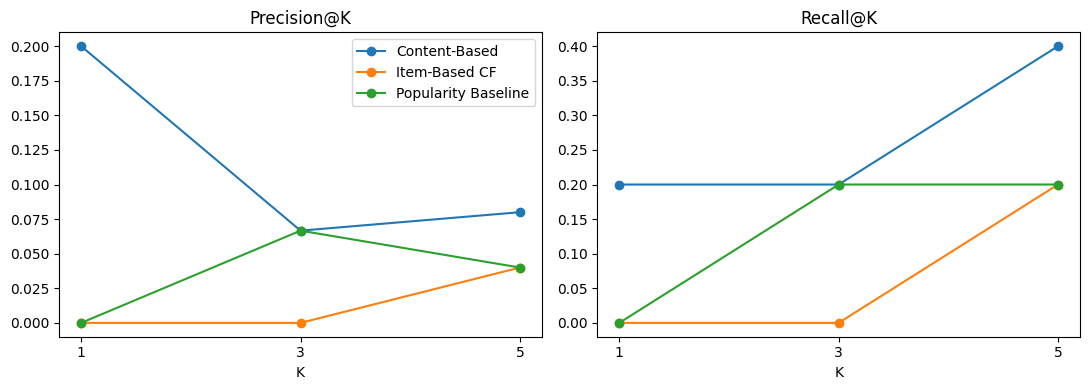

In [42]:
rows = []
for k in [1, 3, 5]:
    for name, rec in [
        ("Popularity Baseline", recommend_popularity),
        ("Content-Based", recommend_content),
        ("Item-Based CF", recommend_cf)
    ]:
        res = list(evaluate_ranking(rec, k).values())
        rows.append({
            "K": k, "Model": name,
            "Precision@K": res[0], "Recall@K": res[1], "NDCG@K": res[2]
        })

k_results = pd.DataFrame(rows)
display(k_results)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, grp in k_results.groupby("Model"):
    axes[0].plot(grp["K"], grp["Precision@K"], marker="o", label=name)
    axes[1].plot(grp["K"], grp["Recall@K"], marker="o", label=name)
axes[0].set_title("Precision@K"); axes[1].set_title("Recall@K")
for ax in axes:
    ax.set_xlabel("K"); ax.set_xticks([1, 3, 5])
axes[0].legend()
plt.tight_layout()
plt.show()

**Explanation:**
- **Precision@K mostly goes down as K grows**. Each user has at most one relevant held-out movie, so the best possible precision is 1/K (1.0 at K=1, 0.33 at K=3, 0.2 at K=5). A longer list adds more slots that are not hits.
- **Recall@K goes up (or stays the same) as K grows.** A longer list gives more chances to catch the relevant movie. Content-Based recall rose from 0.2 to 0.4 at K=5; Popularity and CF stayed at 0.2 at K=5 (CF only began to find a hit at K=5).
- **Note:** At K=1 only Content-Based found a hit. The results are based on just 5 users, so small changes look big.